# VCU Log Summary

Edit `DATA_DIR` in the user block, then run all cells. The loader groups `LOG####_fast.csv`, `LOG####_medium.csv`, `LOG####_slow.csv`, and optional `LOG####_imu.csv` files by numeric log number.

In [1]:
from pathlib import Path
import math
import re

try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

import matplotlib.pyplot as plt
import pandas as pd


LOG_FILE_RE = re.compile(
    r"^(LOG(?P<num>\d+))_(?P<stream>fast|medium|slow|imu)\.csv$",
    re.IGNORECASE,
)
STREAM_ORDER = ("fast", "medium", "slow", "imu")

METRIC_SPECS = [
    ("fast", "bus_current_a", "HV bus current", "A"),
    ("fast", "bus_voltage_v", "HV bus voltage", "V"),
    ("fast", "commanded_torque_nm", "Commanded torque", "Nm"),
    ("medium", "power_kw", "Power", "kW"),
    ("fast", "motor_rpm", "Motor RPM", "rpm"),
    ("slow", "avg_cell_temp_c", "Avg battery cell temp", "C"),
    ("medium", "battery_temp_c", "Reported battery temp", "C"),
    ("medium", "inverter_temp_c", "Inverter temp", "C"),
    ("medium", "motor_temp_c", "Motor temp", "C"),
]


def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "VCU").exists() and (path / "README.md").exists():
            return path
    return start


REPO_ROOT = find_repo_root()


def resolve_data_dir(data_dir):
    path = Path(data_dir).expanduser()
    if path.is_absolute():
        return path

    candidates = [
        Path.cwd() / path,
        REPO_ROOT / path,
        REPO_ROOT / "VCU" / path,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    return (REPO_ROOT / path).resolve()


def _with_elapsed_seconds(df):
    df = df.copy()
    if "t_ms" not in df.columns:
        return df

    t_ms = pd.to_numeric(df["t_ms"], errors="coerce")
    valid_t = t_ms.dropna()
    if valid_t.empty:
        return df

    df.insert(1, "elapsed_s", (t_ms - valid_t.iloc[0]) / 1000.0)
    return df


def _numeric(series):
    values = pd.to_numeric(series, errors="coerce")
    return values.mask(values <= -999)


def _stream_sort_key(stream):
    try:
        return STREAM_ORDER.index(stream)
    except ValueError:
        return len(STREAM_ORDER)


def load_vcu_logs(data_dir, recursive=False, verbose=True):
    """Load every decoded VCU CSV in data_dir and group them by LOG number."""
    data_dir = resolve_data_dir(data_dir)
    if not data_dir.exists():
        raise FileNotFoundError(f"Directory not found: {data_dir}")

    csv_paths = sorted(data_dir.rglob("*.csv") if recursive else data_dir.glob("*.csv"))
    groups = {}
    skipped = []

    for path in csv_paths:
        match = LOG_FILE_RE.match(path.name)
        if not match:
            skipped.append(path)
            continue

        log_num = int(match.group("num"))
        log_id = f"LOG{log_num:04d}"
        stream = match.group("stream").lower()
        entry = groups.setdefault(
            log_num,
            {"log_id": log_id, "directory": data_dir, "files": {}, "data": {}},
        )
        if stream in entry["data"]:
            raise ValueError(f"Duplicate {stream} CSV for {log_id}: {path}")

        entry["files"][stream] = path
        entry["data"][stream] = _with_elapsed_seconds(pd.read_csv(path))

    if not groups:
        raise FileNotFoundError(f"No decoded LOG#### CSV files found in {data_dir}")

    logs = {num: groups[num] for num in sorted(groups)}
    for entry in logs.values():
        streams = tuple(sorted(entry["data"], key=_stream_sort_key))
        entry["streams"] = streams
        entry["row_counts"] = {stream: len(entry["data"][stream]) for stream in streams}

    if verbose:
        print(f"Loaded {len(logs)} LOG groups from {data_dir}")
        if skipped:
            print(f"Skipped {len(skipped)} CSV file(s) that did not match LOG####_<stream>.csv")
        display_loaded_logs(logs)

    return logs


def display_loaded_logs(logs):
    rows = []
    for log_num, log in sorted(logs.items()):
        row = {"log_num": log_num, "log_id": log["log_id"], "streams": ", ".join(log["streams"])}
        for stream in STREAM_ORDER:
            row[f"{stream}_rows"] = log["row_counts"].get(stream, 0)
        rows.append(row)
    display(pd.DataFrame(rows))


def log_duration_s(log):
    starts = []
    ends = []
    for df in log["data"].values():
        if "t_ms" not in df.columns:
            continue
        t_ms = pd.to_numeric(df["t_ms"], errors="coerce").dropna()
        if not t_ms.empty:
            starts.append(t_ms.min())
            ends.append(t_ms.max())
    if not starts or not ends:
        return math.nan
    return (max(ends) - min(starts)) / 1000.0


def compute_log_metrics(log):
    rows = []
    for stream, column, label, unit in METRIC_SPECS:
        df = log["data"].get(stream)
        if df is None or column not in df.columns:
            continue
        values = _numeric(df[column]).dropna()
        if values.empty:
            continue
        rows.append(
            {
                "signal": label,
                "stream": stream,
                "unit": unit,
                "samples": int(values.count()),
                "average": values.mean(),
                "maximum": values.max(),
                "minimum": values.min(),
            }
        )
    return pd.DataFrame(rows)


def print_log_metrics(log):
    print(f"\n{log['log_id']}")
    print("Streams: " + ", ".join(log["streams"]))
    print("Rows: " + ", ".join(f"{stream}={count:,}" for stream, count in log["row_counts"].items()))
    duration = log_duration_s(log)
    if math.isfinite(duration):
        print(f"Duration: {duration:,.1f} s")

    metrics = compute_log_metrics(log)
    if metrics.empty:
        print("No numeric metrics found for this log.")
        return metrics

    display(metrics.round({"average": 2, "maximum": 2, "minimum": 2}))
    return metrics


def _downsample(df, max_points):
    if not max_points or len(df) <= max_points:
        return df
    step = math.ceil(len(df) / max_points)
    return df.iloc[::step].copy()


def _x_values(df):
    if "elapsed_s" in df.columns:
        return pd.to_numeric(df["elapsed_s"], errors="coerce")
    if "t_ms" in df.columns:
        t_ms = pd.to_numeric(df["t_ms"], errors="coerce")
        valid_t = t_ms.dropna()
        if not valid_t.empty:
            return (t_ms - valid_t.iloc[0]) / 1000.0
    return pd.Series(df.index, index=df.index)


def _plot_signal(ax, log, stream, column, label, color=None, linestyle="-", max_points=5000):
    df = log["data"].get(stream)
    if df is None or column not in df.columns:
        return None

    plot_df = _downsample(df, max_points)
    x = _x_values(plot_df)
    y = _numeric(plot_df[column])
    if y.dropna().empty:
        return None
    line, = ax.plot(x, y, label=label, color=color, linestyle=linestyle, linewidth=1.2)
    return line


def _plot_first_available(ax, log, candidates, label, color=None, linestyle="-", max_points=5000):
    for stream, column in candidates:
        line = _plot_signal(ax, log, stream, column, label, color, linestyle, max_points)
        if line is not None:
            return line
    return None


def _combined_legend(*axes):
    lines = []
    labels = []
    for ax in axes:
        ax_lines, ax_labels = ax.get_legend_handles_labels()
        lines.extend(ax_lines)
        labels.extend(ax_labels)
    if lines:
        axes[0].legend(lines, labels, loc="best")


def _mark_empty(ax, lines, message):
    if not any(line is not None for line in lines):
        ax.text(0.5, 0.5, message, ha="center", va="center", transform=ax.transAxes)


def plot_log_summary(log, max_points=5000):
    fig, axes = plt.subplots(3, 1, figsize=(13, 10), constrained_layout=True)
    fig.suptitle(f"{log['log_id']} VCU summary", fontsize=14)

    ax = axes[0]
    ax.set_title("HV bus current and voltage")
    current = _plot_first_available(
        ax,
        log,
        [("fast", "bus_current_a"), ("fast", "raw_hv_current")],
        "HV bus current (A)",
        color="tab:blue",
        max_points=max_points,
    )
    ax.set_ylabel("Current (A)")
    ax.grid(True, alpha=0.25)

    voltage_ax = ax.twinx()
    voltage = _plot_signal(
        voltage_ax,
        log,
        "fast",
        "bus_voltage_v",
        "HV bus voltage (V)",
        color="tab:orange",
        max_points=max_points,
    )
    voltage_ax.set_ylabel("Voltage (V)")
    _combined_legend(ax, voltage_ax)
    _mark_empty(ax, [current, voltage], "No HV bus current or voltage data")

    ax = axes[1]
    ax.set_title("Torque, power, and motor RPM")
    torque = _plot_first_available(
        ax,
        log,
        [("fast", "commanded_torque_nm"), ("medium", "desired_torque_nm")],
        "Commanded torque (Nm)",
        color="tab:green",
        max_points=max_points,
    )
    power = _plot_signal(
        ax,
        log,
        "medium",
        "power_kw",
        "Power (kW)",
        color="tab:red",
        max_points=max_points,
    )
    ax.set_ylabel("Torque (Nm) / Power (kW)")
    ax.grid(True, alpha=0.25)

    rpm_ax = ax.twinx()
    rpm = _plot_signal(
        rpm_ax,
        log,
        "fast",
        "motor_rpm",
        "Motor RPM",
        color="tab:purple",
        max_points=max_points,
    )
    rpm_ax.set_ylabel("RPM")
    _combined_legend(ax, rpm_ax)
    _mark_empty(ax, [torque, power, rpm], "No torque, power, or RPM data")

    ax = axes[2]
    ax.set_title("Average/reported temperatures")
    battery = _plot_first_available(
        ax,
        log,
        [("slow", "avg_cell_temp_c"), ("medium", "battery_temp_c")],
        "Battery average temp (C)",
        color="tab:cyan",
        max_points=max_points,
    )
    inverter = _plot_signal(
        ax,
        log,
        "medium",
        "inverter_temp_c",
        "Inverter temp (C)",
        color="tab:pink",
        max_points=max_points,
    )
    motor = _plot_signal(
        ax,
        log,
        "medium",
        "motor_temp_c",
        "Motor temp (C)",
        color="tab:brown",
        max_points=max_points,
    )
    ax.set_ylabel("Temperature (C)")
    ax.set_xlabel("Elapsed time (s)")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    _mark_empty(ax, [battery, inverter, motor], "No temperature data")

    plt.show()
    return fig, axes


def summarize_vcu_logs(logs, log_numbers=None, max_points=5000):
    """Print metrics and plot the three requested subplots for each selected LOG."""
    selected = sorted(logs) if log_numbers is None else sorted(int(num) for num in log_numbers)
    metrics_by_log = {}
    for log_num in selected:
        log = logs[log_num]
        metrics_by_log[log_num] = print_log_metrics(log)
        plot_log_summary(log, max_points=max_points)
    return metrics_by_log


## User Block

In [2]:
# Change this to the directory containing decoded LOG#### CSV files.
DATA_DIR = r"VCU/June11thTestingDataLog_AfterChargingBattery"

# Set to a list such as [1, 2, 8] to plot only certain logs, or leave as None for all logs.
LOG_NUMBERS = None

# Increase this if you want denser plots. Lower values keep large notebooks responsive.
MAX_POINTS_PER_TRACE = 5000

logs = load_vcu_logs(DATA_DIR)


Loaded 14 LOG groups from C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery


,log_num,log_id,streams,fast_rows,medium_rows,slow_rows,imu_rows
0,1,LOG0001,"fast, medium, slow",5361,539,55,0
1,2,LOG0002,"fast, medium, slow, imu",1071,109,12,1071
2,3,LOG0003,"fast, medium, slow, imu",2567,259,27,2567
3,4,LOG0004,"fast, medium, slow, imu",4689,470,48,4689
4,5,LOG0005,"fast, medium, slow, imu",3892,390,40,3892
5,6,LOG0006,"fast, medium, slow, imu",8754,879,89,8754
6,7,LOG0007,"fast, medium, slow, imu",5892,590,60,5892
7,8,LOG0008,"fast, medium, slow, imu",8383,840,85,8383
8,9,LOG0009,"fast, medium, slow, imu",12179,1220,123,12179
9,10,LOG0010,"fast, medium, slow, imu",18897,1980,200,18897


## Metrics And Plots


LOG0001
Streams: fast, medium, slow
Rows: fast=5,361, medium=539, slow=55
Duration: 54.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,5361,0.00,0.0,0.0
1,HV bus voltage,fast,V,5361,0.57,1.3,0.0
2,Commanded torque,fast,Nm,5361,0.00,0.0,0.0
3,Power,medium,kW,539,0.00,0.0,0.0
4,Motor RPM,fast,rpm,5361,0.00,1.0,0.0
5,Reported battery temp,medium,C,539,0.00,0.0,0.0
6,Inverter temp,medium,C,539,22.03,22.2,0.0
7,Motor temp,medium,C,539,28.40,29.1,0.0


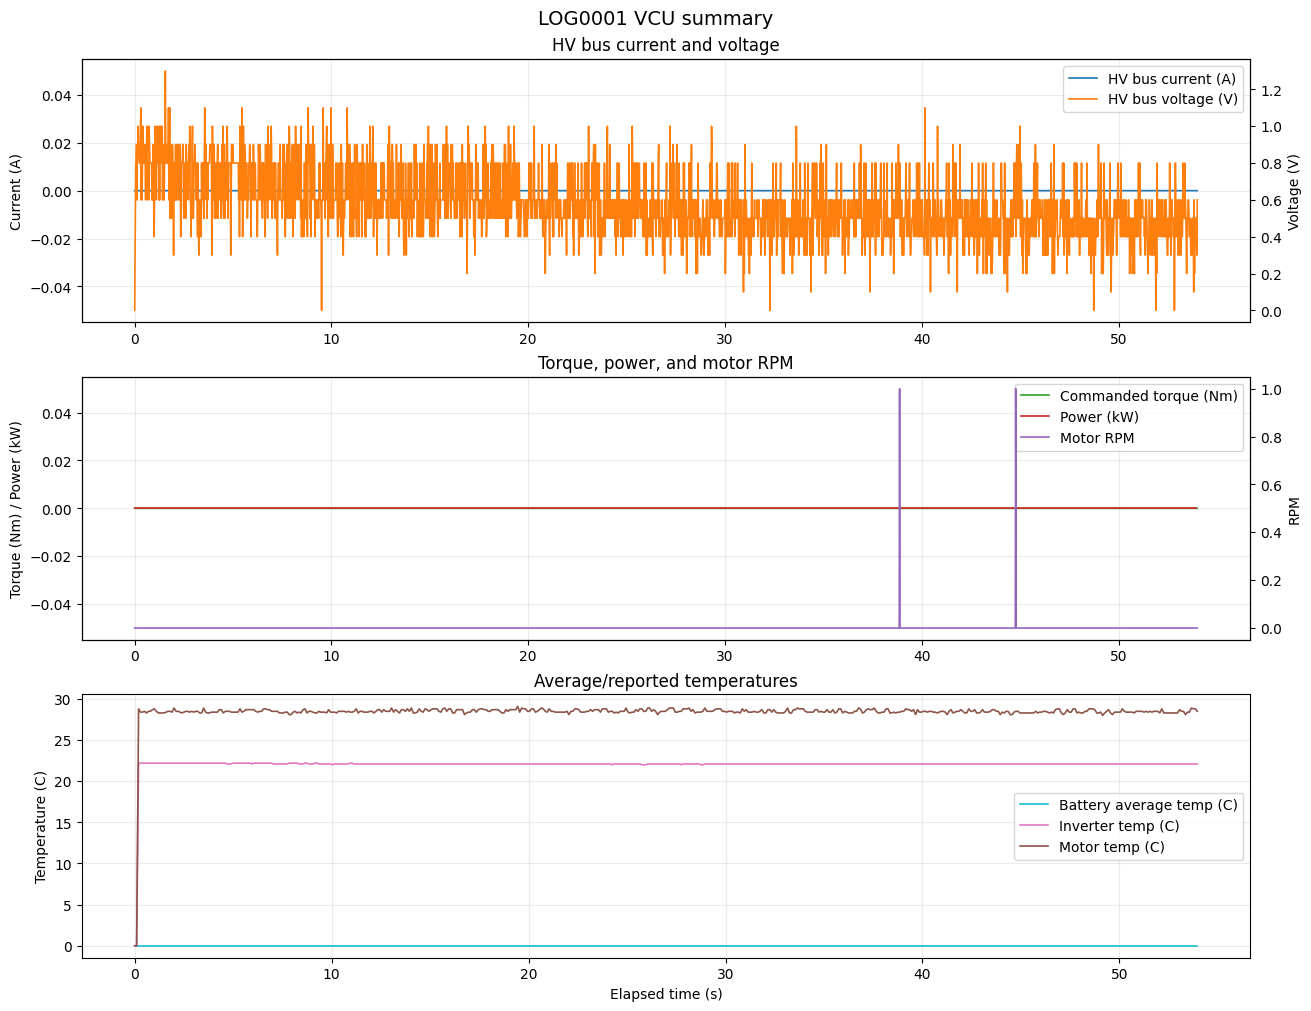


LOG0002
Streams: fast, medium, slow, imu
Rows: fast=1,071, medium=109, slow=12, imu=1,071
Duration: 11.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,1071,0.00,0.0,0.0
1,HV bus voltage,fast,V,1071,0.49,1.0,0.0
2,Commanded torque,fast,Nm,1071,0.00,0.0,0.0
3,Power,medium,kW,109,0.00,0.0,0.0
4,Motor RPM,fast,rpm,1071,0.08,7.0,-1.0
5,Reported battery temp,medium,C,109,0.00,0.0,0.0
6,Inverter temp,medium,C,109,21.71,22.2,0.0
7,Motor temp,medium,C,109,27.87,28.9,0.0


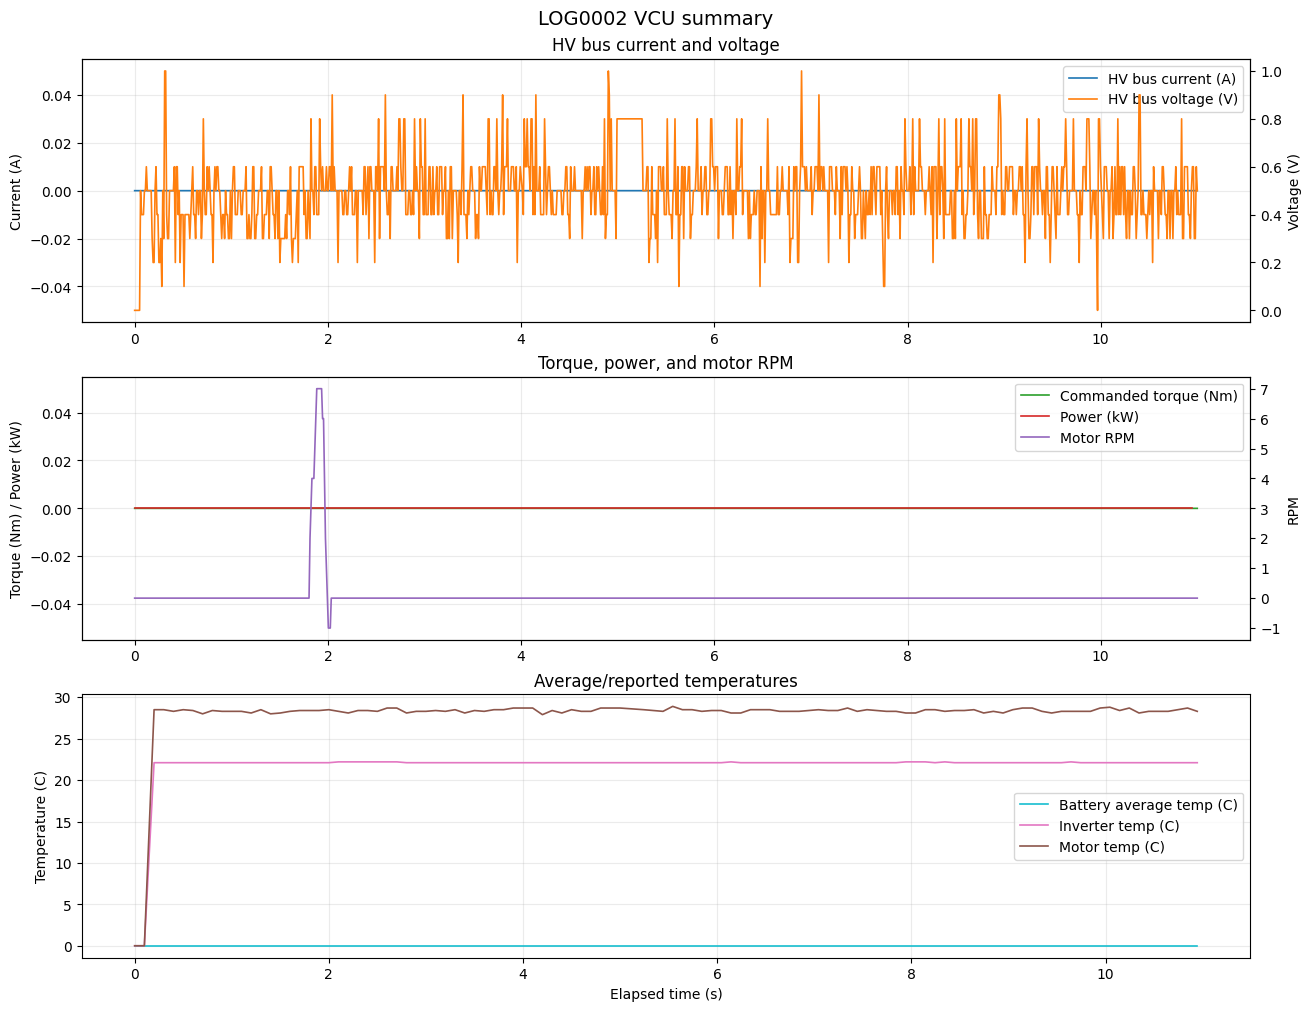


LOG0003
Streams: fast, medium, slow, imu
Rows: fast=2,567, medium=259, slow=27, imu=2,567
Duration: 26.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,2567,0.00,0.0,0.0
1,HV bus voltage,fast,V,2567,0.44,1.1,0.0
2,Commanded torque,fast,Nm,2567,0.00,0.0,0.0
3,Power,medium,kW,259,0.00,0.0,0.0
4,Motor RPM,fast,rpm,2567,-0.00,1.0,-1.0
5,Reported battery temp,medium,C,259,0.00,0.0,0.0
6,Inverter temp,medium,C,259,21.95,22.2,0.0
7,Motor temp,medium,C,259,28.17,28.9,0.0


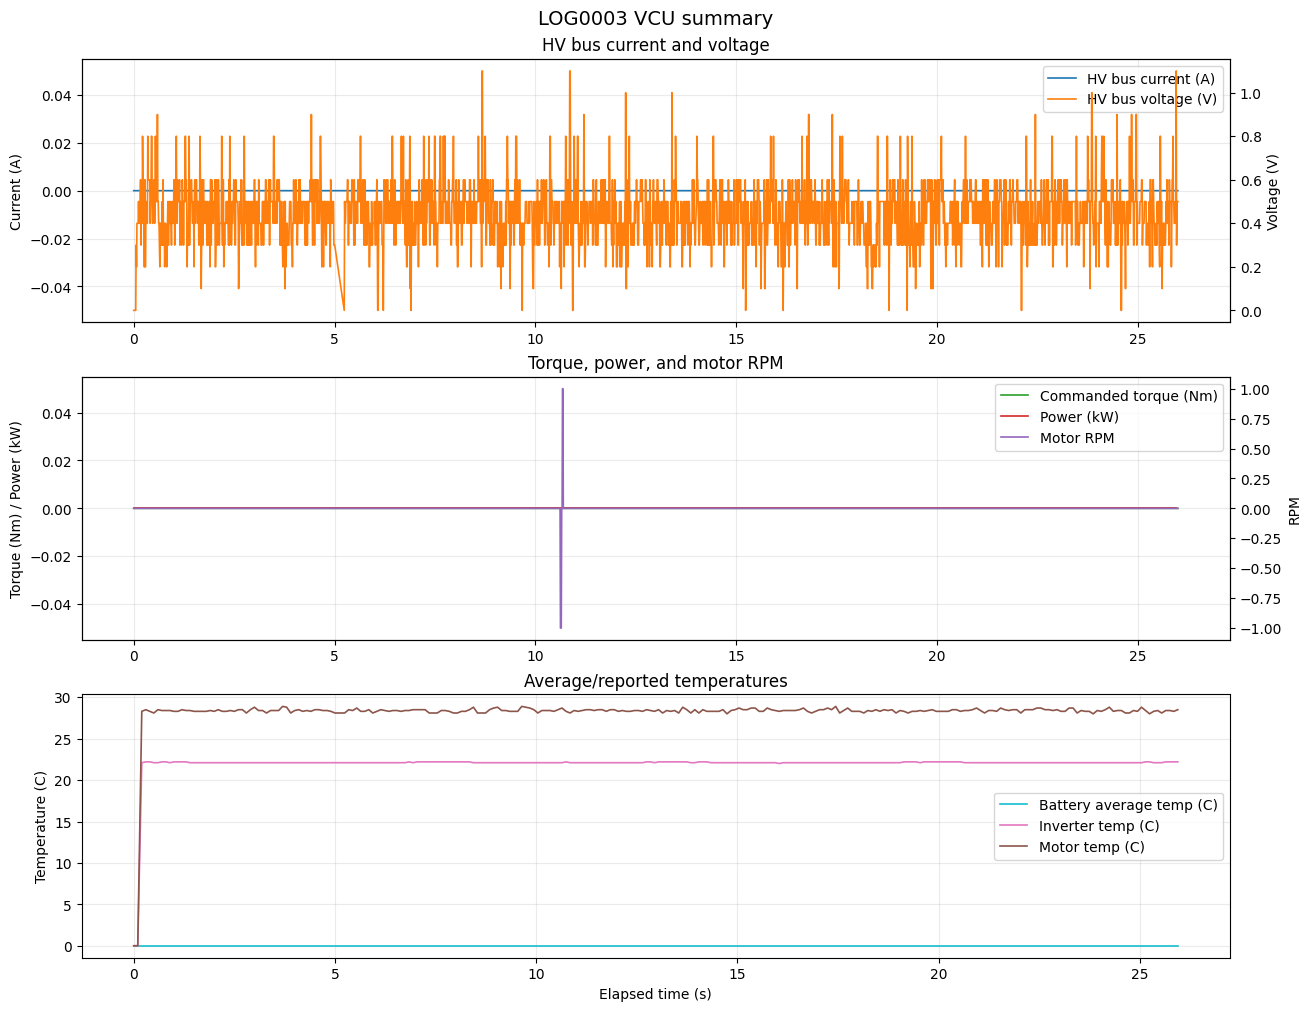


LOG0004
Streams: fast, medium, slow, imu
Rows: fast=4,689, medium=470, slow=48, imu=4,689
Duration: 47.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,4689,0.00,0.0,0.0
1,HV bus voltage,fast,V,4689,0.57,1.2,0.0
2,Commanded torque,fast,Nm,4689,0.00,0.0,0.0
3,Power,medium,kW,470,0.00,0.0,0.0
4,Motor RPM,fast,rpm,4689,0.00,0.0,0.0
5,Avg battery cell temp,slow,C,44,30.00,30.0,30.0
6,Reported battery temp,medium,C,470,29.31,32.0,0.0
7,Inverter temp,medium,C,470,22.20,22.3,0.0
8,Motor temp,medium,C,470,27.16,27.9,0.0


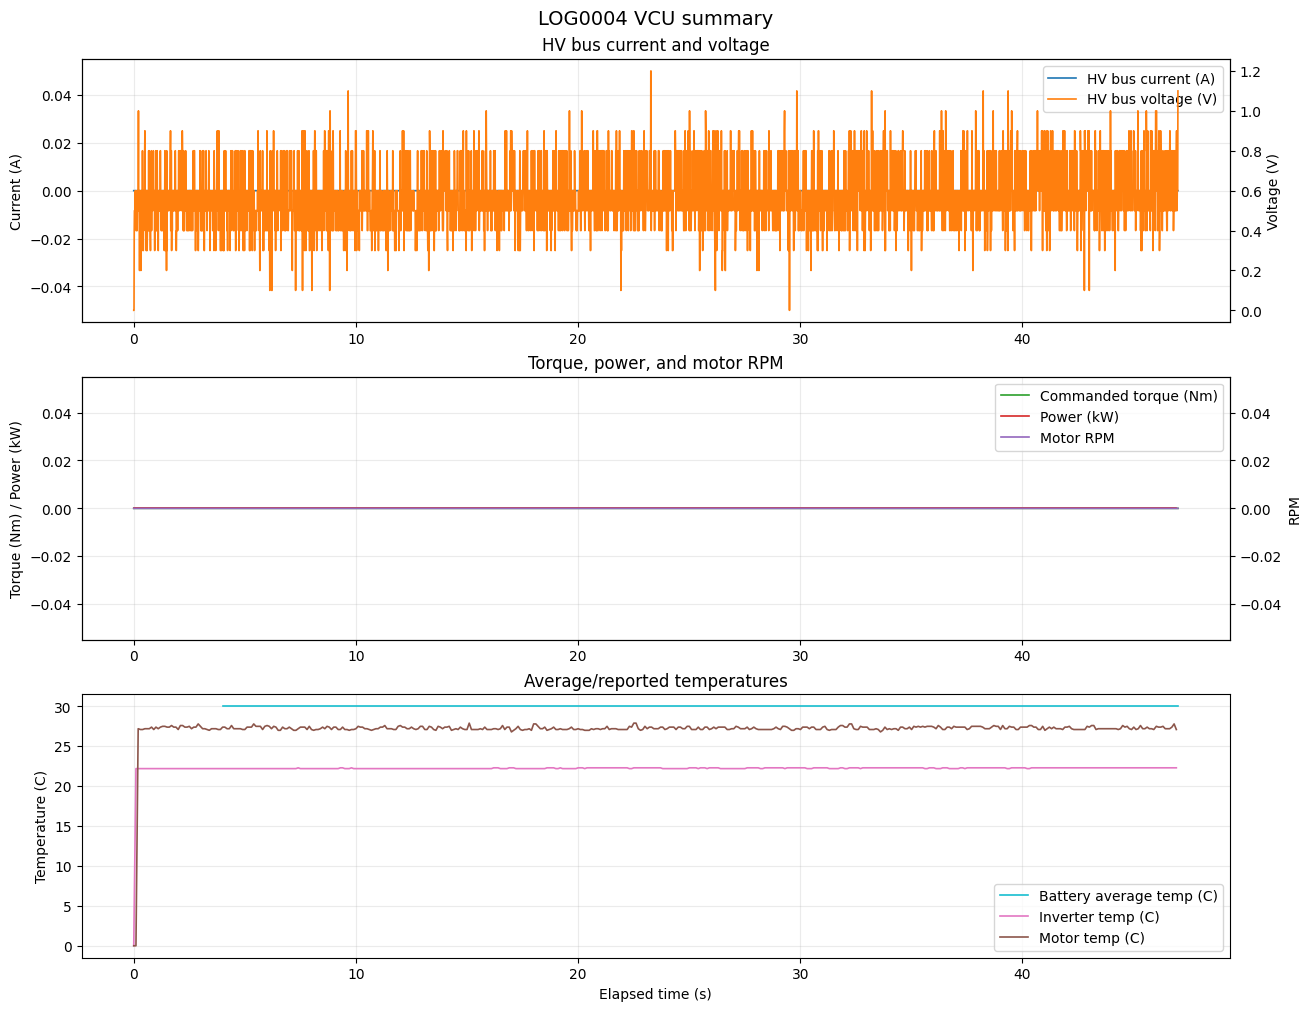


LOG0005
Streams: fast, medium, slow, imu
Rows: fast=3,892, medium=390, slow=40, imu=3,892
Duration: 39.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,3892,0.00,0.0,0.0
1,HV bus voltage,fast,V,3892,0.60,1.2,0.0
2,Commanded torque,fast,Nm,3892,0.00,0.0,0.0
3,Power,medium,kW,390,0.00,0.0,0.0
4,Motor RPM,fast,rpm,3892,0.00,0.0,0.0
5,Avg battery cell temp,slow,C,35,30.00,30.0,30.0
6,Reported battery temp,medium,C,390,27.26,31.0,0.0
7,Inverter temp,medium,C,390,22.22,22.4,0.0
8,Motor temp,medium,C,390,27.22,27.9,0.0


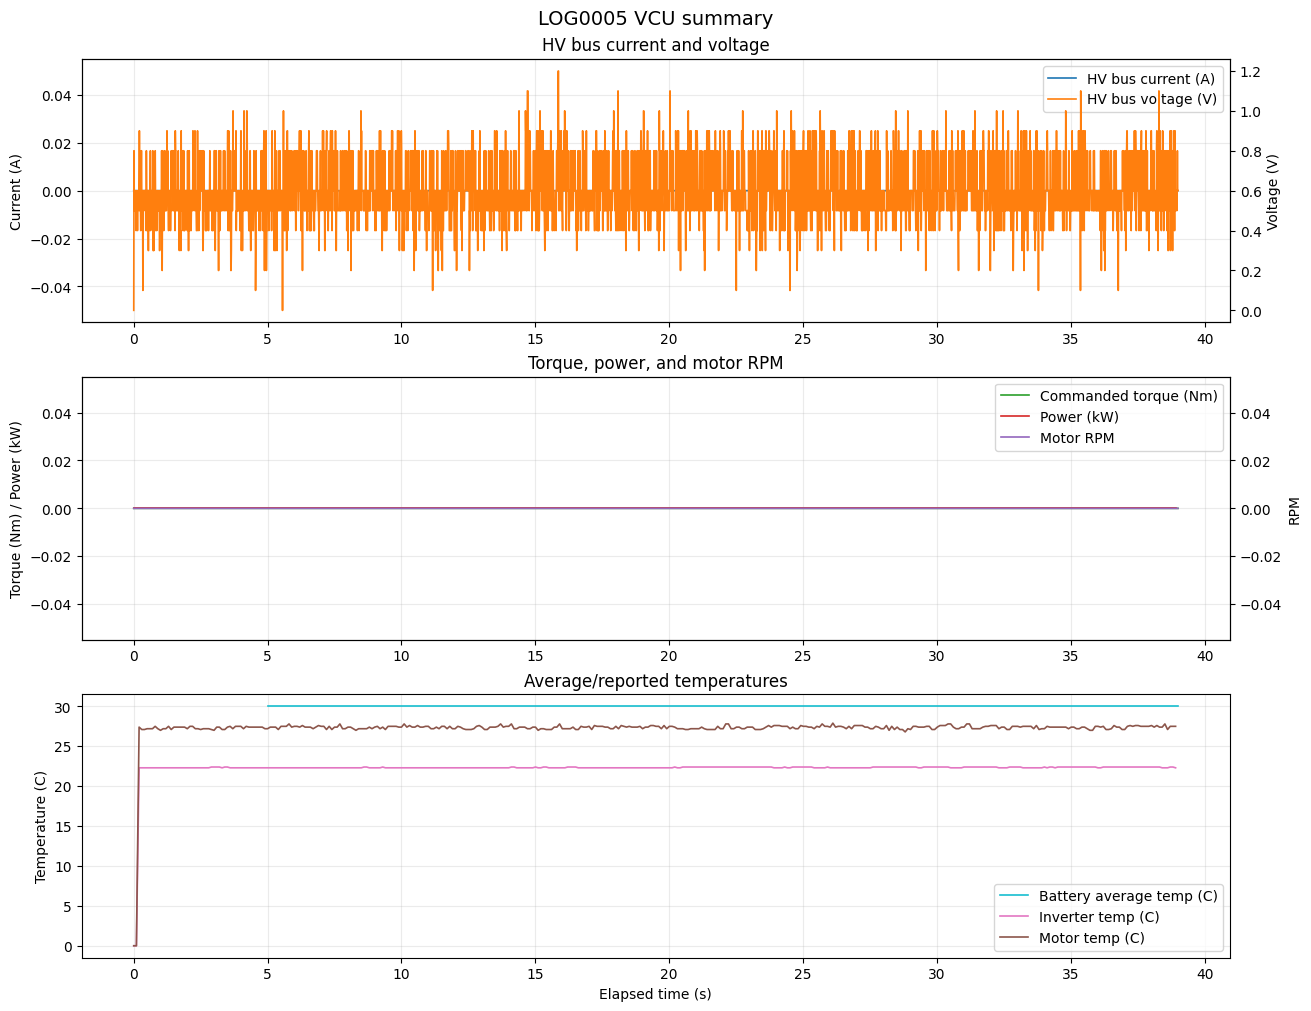


LOG0006
Streams: fast, medium, slow, imu
Rows: fast=8,754, medium=879, slow=89, imu=8,754
Duration: 88.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,8754,-0.01,0.0,-40.4
1,HV bus voltage,fast,V,8754,0.62,1.3,0.0
2,Commanded torque,fast,Nm,8754,0.00,0.0,0.0
3,Power,medium,kW,879,0.00,0.0,0.0
4,Motor RPM,fast,rpm,8754,0.00,0.0,0.0
5,Avg battery cell temp,slow,C,85,30.00,30.0,30.0
6,Reported battery temp,medium,C,879,29.87,31.0,0.0
7,Inverter temp,medium,C,879,22.62,23.2,0.0
8,Motor temp,medium,C,879,27.38,28.3,0.0


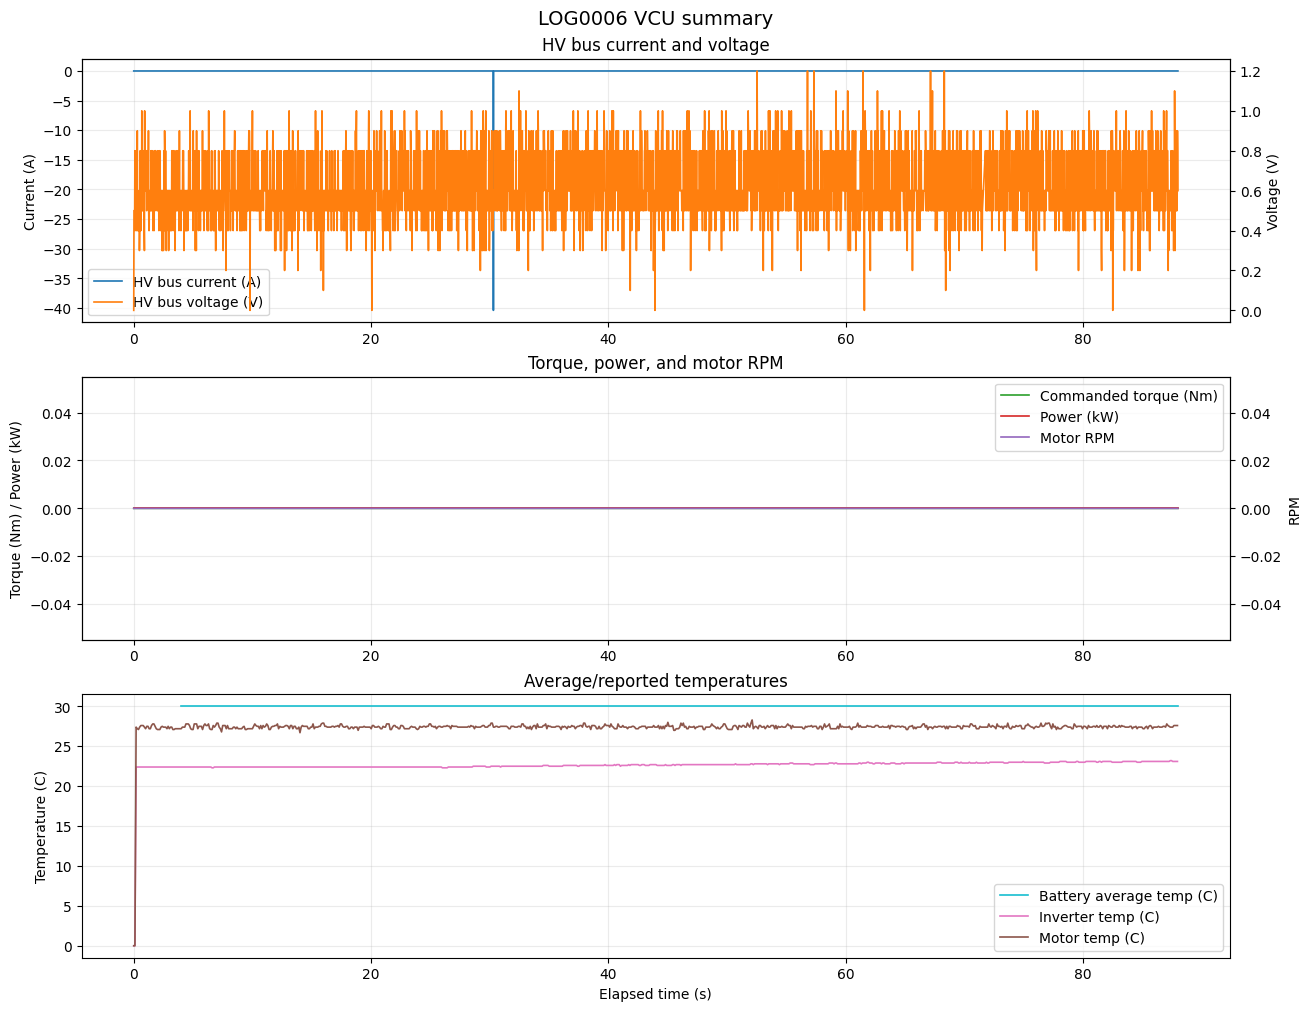


LOG0007
Streams: fast, medium, slow, imu
Rows: fast=5,892, medium=590, slow=60, imu=5,892
Duration: 59.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,5892,0.00,0.0,0.0
1,HV bus voltage,fast,V,5892,0.68,1.4,0.0
2,Commanded torque,fast,Nm,5892,0.00,0.0,0.0
3,Power,medium,kW,590,0.00,0.0,0.0
4,Motor RPM,fast,rpm,5892,0.00,0.0,0.0
5,Avg battery cell temp,slow,C,55,29.00,29.0,29.0
6,Reported battery temp,medium,C,590,28.79,31.0,0.0
7,Inverter temp,medium,C,590,22.68,23.3,0.0
8,Motor temp,medium,C,590,28.05,202.6,0.0


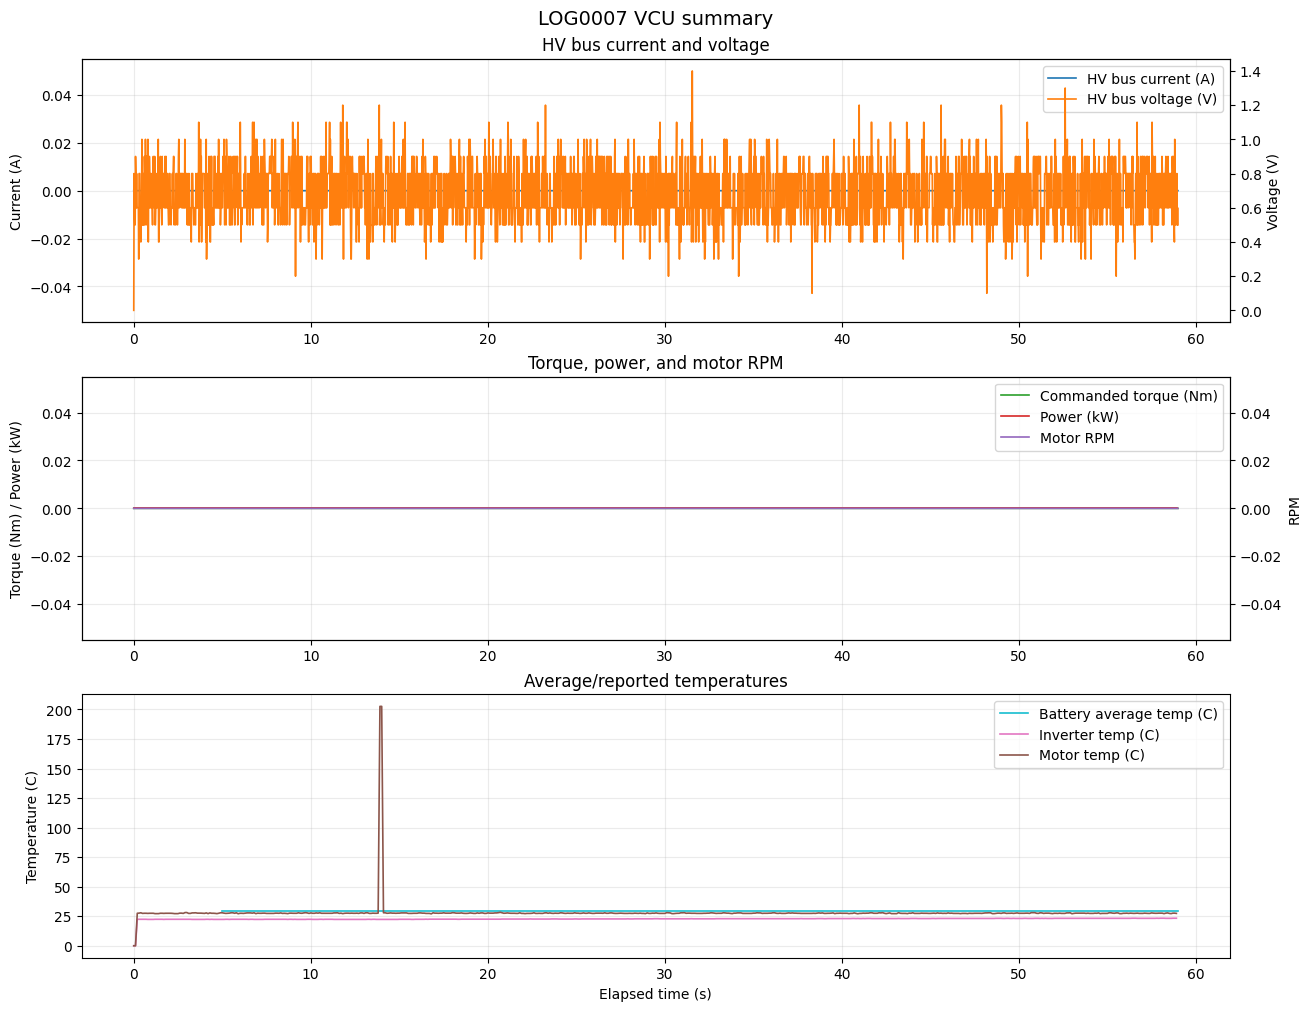


LOG0008
Streams: fast, medium, slow, imu
Rows: fast=8,383, medium=840, slow=85, imu=8,383
Duration: 84.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,8383,0.00,0.0,0.0
1,HV bus voltage,fast,V,8383,9.72,307.1,0.0
2,Commanded torque,fast,Nm,8383,0.00,0.0,0.0
3,Power,medium,kW,840,0.00,0.0,0.0
4,Motor RPM,fast,rpm,8383,0.00,0.0,0.0
5,Avg battery cell temp,slow,C,81,26.00,26.0,26.0
6,Reported battery temp,medium,C,840,25.81,27.0,0.0
7,Inverter temp,medium,C,840,21.89,22.2,0.0
8,Motor temp,medium,C,840,26.86,27.5,0.0


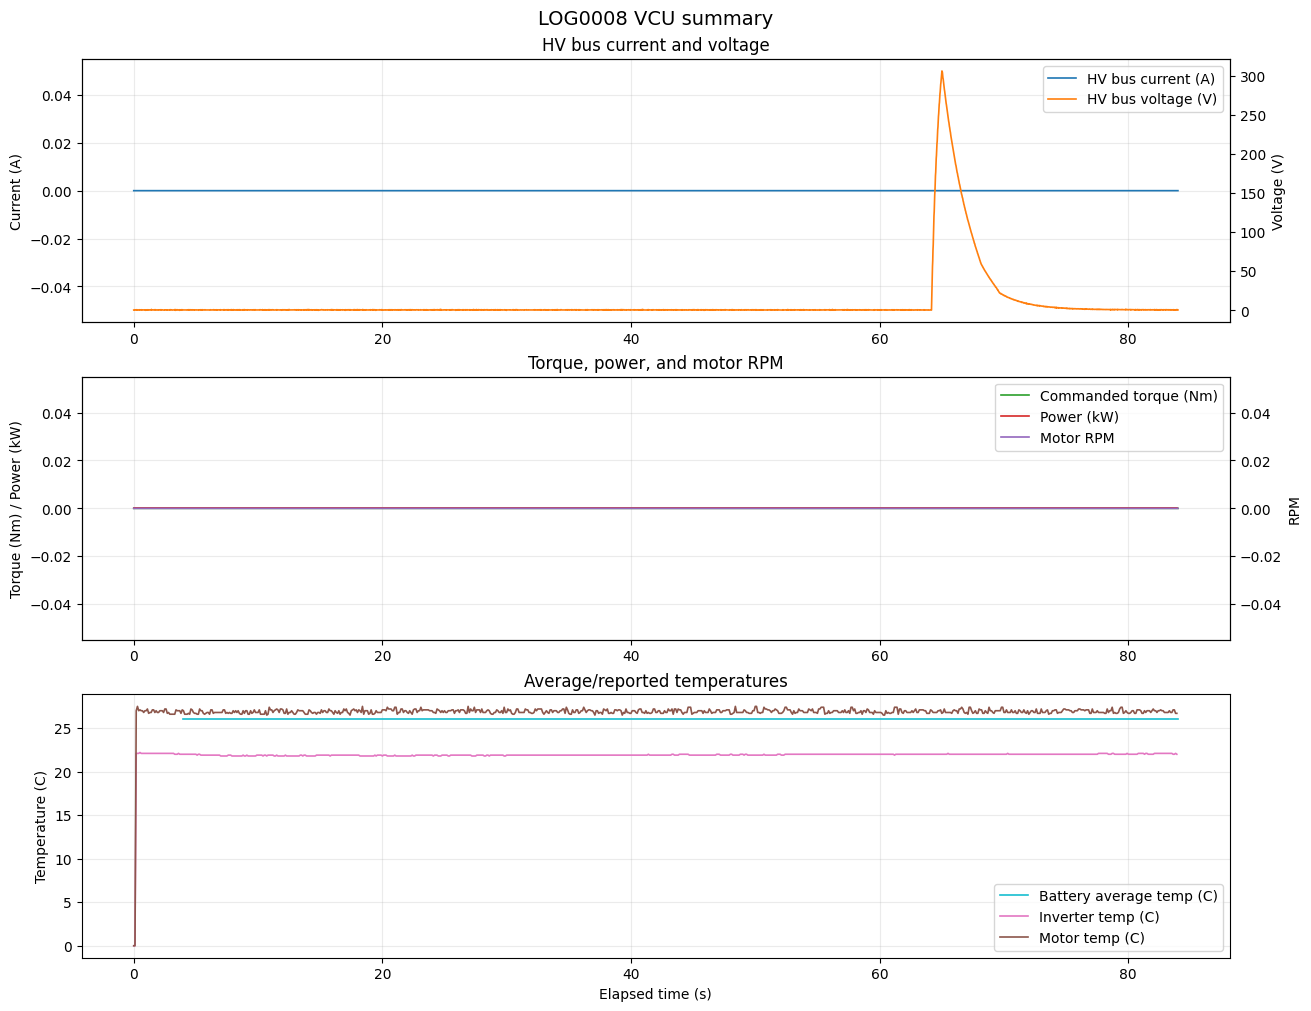


LOG0009
Streams: fast, medium, slow, imu
Rows: fast=12,179, medium=1,220, slow=123, imu=12,179
Duration: 122.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,12179,0.00,0.0,0.0
1,HV bus voltage,fast,V,12179,11.20,378.2,0.0
2,Commanded torque,fast,Nm,12179,0.00,0.0,0.0
3,Power,medium,kW,1220,0.00,0.0,0.0
4,Motor RPM,fast,rpm,12179,0.00,0.0,0.0
5,Avg battery cell temp,slow,C,118,26.00,26.0,26.0
6,Reported battery temp,medium,C,1220,26.07,27.0,0.0
7,Inverter temp,medium,C,1220,22.14,22.6,0.0
8,Motor temp,medium,C,1220,27.07,27.8,0.0


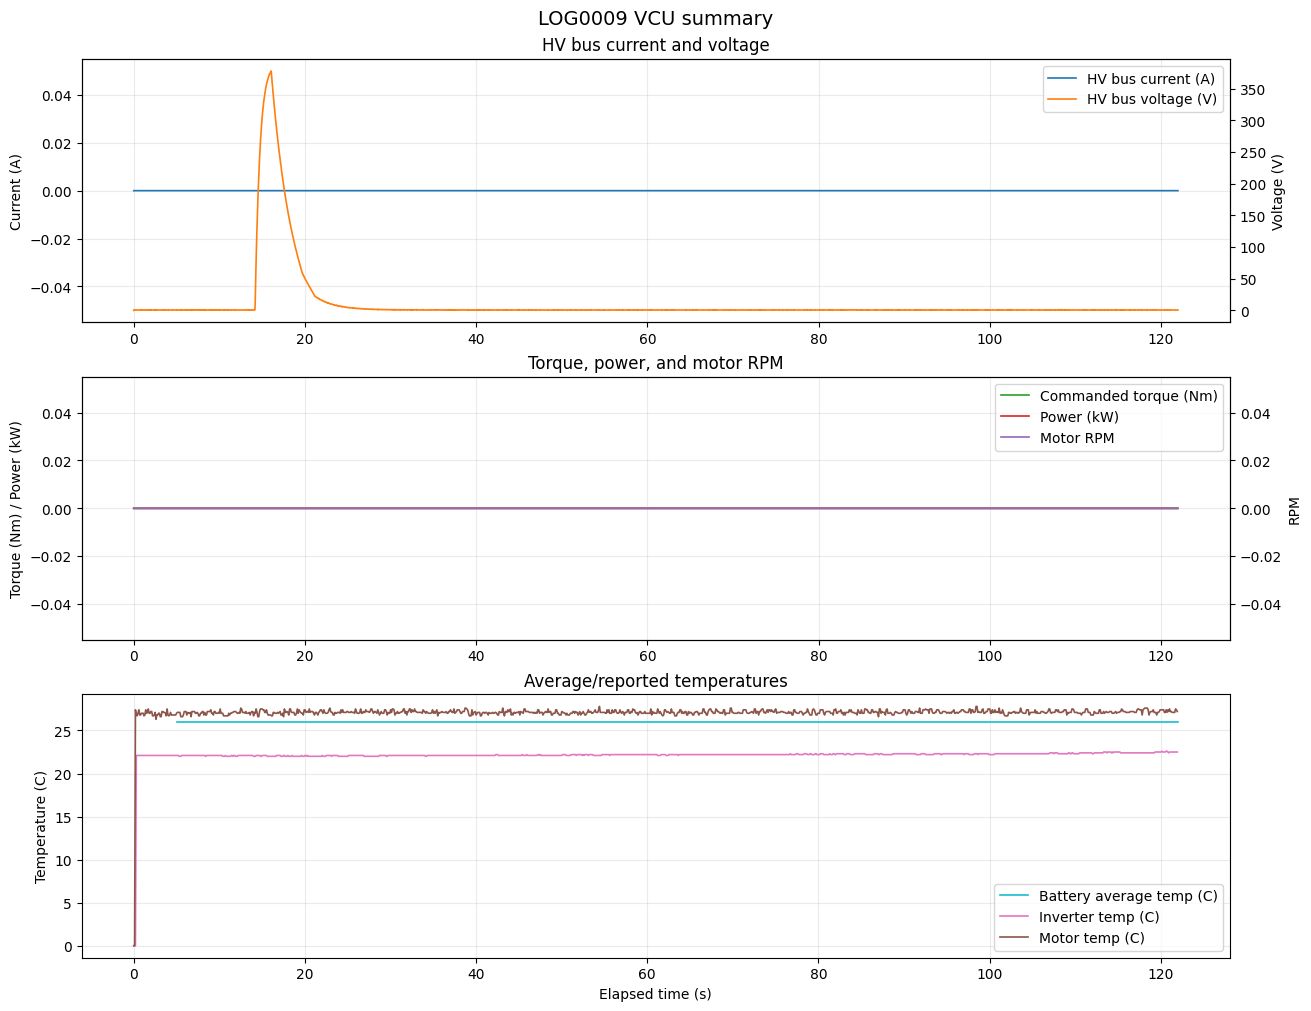


LOG0010
Streams: fast, medium, slow, imu
Rows: fast=18,897, medium=1,980, slow=200, imu=18,897
Duration: 199.1 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,18897,4.84,164.9,-0.6
1,HV bus voltage,fast,V,18897,188.24,402.8,0.1
2,Commanded torque,fast,Nm,18897,11.95,208.6,0.0
3,Power,medium,kW,1980,2.17,56.0,-0.2
4,Motor RPM,fast,rpm,18897,457.23,3396.0,-80.0
5,Avg battery cell temp,slow,C,196,26.00,26.0,26.0
6,Reported battery temp,medium,C,1980,26.56,27.0,0.0
7,Inverter temp,medium,C,1980,25.16,30.2,0.0
8,Motor temp,medium,C,1980,30.71,34.4,0.0


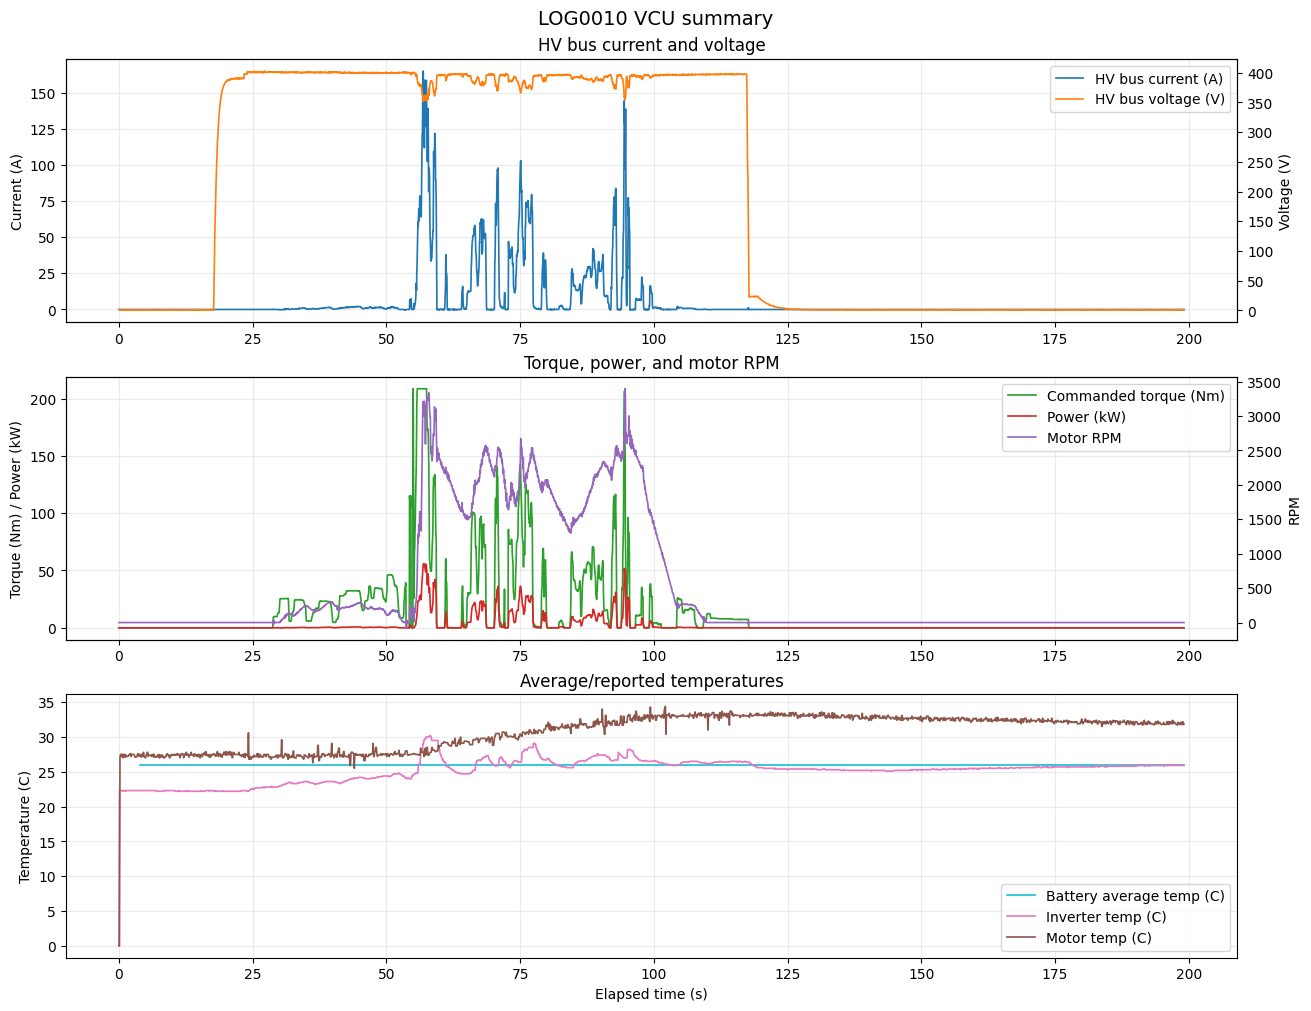


LOG0011
Streams: fast, medium, slow, imu
Rows: fast=36,954, medium=3,961, slow=400, imu=36,954
Duration: 399.4 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,36954,7.05,152.0,-0.5
1,HV bus voltage,fast,V,36954,293.81,400.0,0.0
2,Commanded torque,fast,Nm,36954,21.30,207.9,0.0
3,Power,medium,kW,3961,2.98,51.7,-0.2
4,Motor RPM,fast,rpm,36954,668.26,3296.0,-10.0
5,Avg battery cell temp,slow,C,396,26.00,26.0,26.0
6,Reported battery temp,medium,C,3961,26.75,27.0,0.0
7,Inverter temp,medium,C,3961,29.10,34.5,0.0
8,Motor temp,medium,C,3961,35.28,42.7,0.0


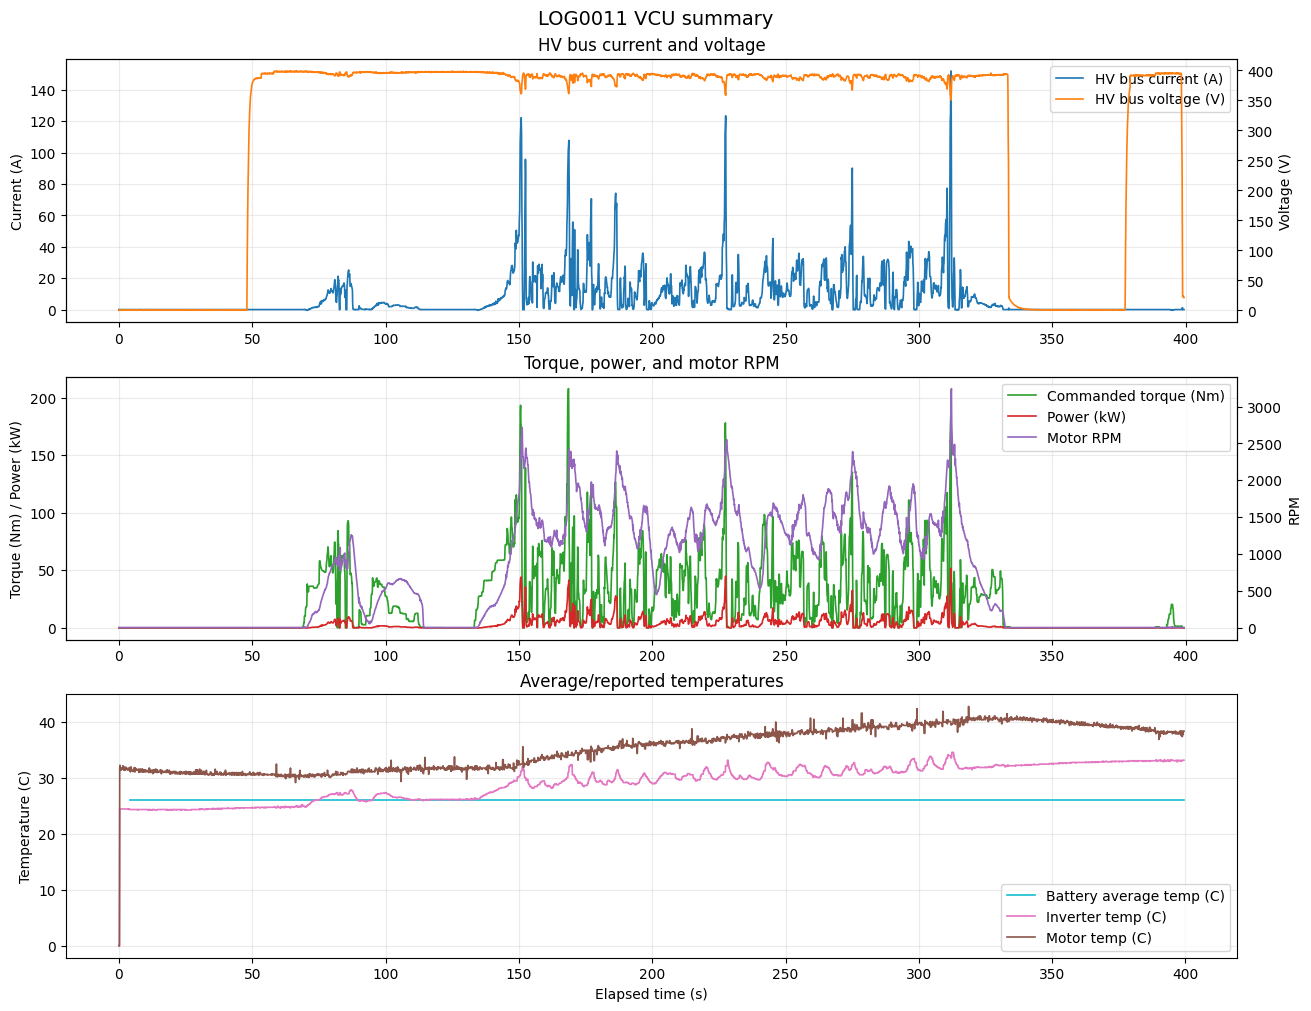


LOG0012
Streams: fast, medium, slow, imu
Rows: fast=95,211, medium=10,533, slow=1,066, imu=95,211
Duration: 1,066.3 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,95211,19.14,169.4,-167.4
1,HV bus voltage,fast,V,95211,216.60,397.0,0.0
2,Commanded torque,fast,Nm,95211,34.35,210.0,0.0
3,Power,medium,kW,10533,7.66,58.0,-0.4
4,Motor RPM,fast,rpm,95211,1071.09,3481.0,-294.0
5,Avg battery cell temp,slow,C,1061,33.85,39.0,26.0
6,Reported battery temp,medium,C,10533,36.35,42.0,0.0
7,Inverter temp,medium,C,10533,43.59,55.9,0.0
8,Motor temp,medium,C,10533,53.68,71.1,0.0


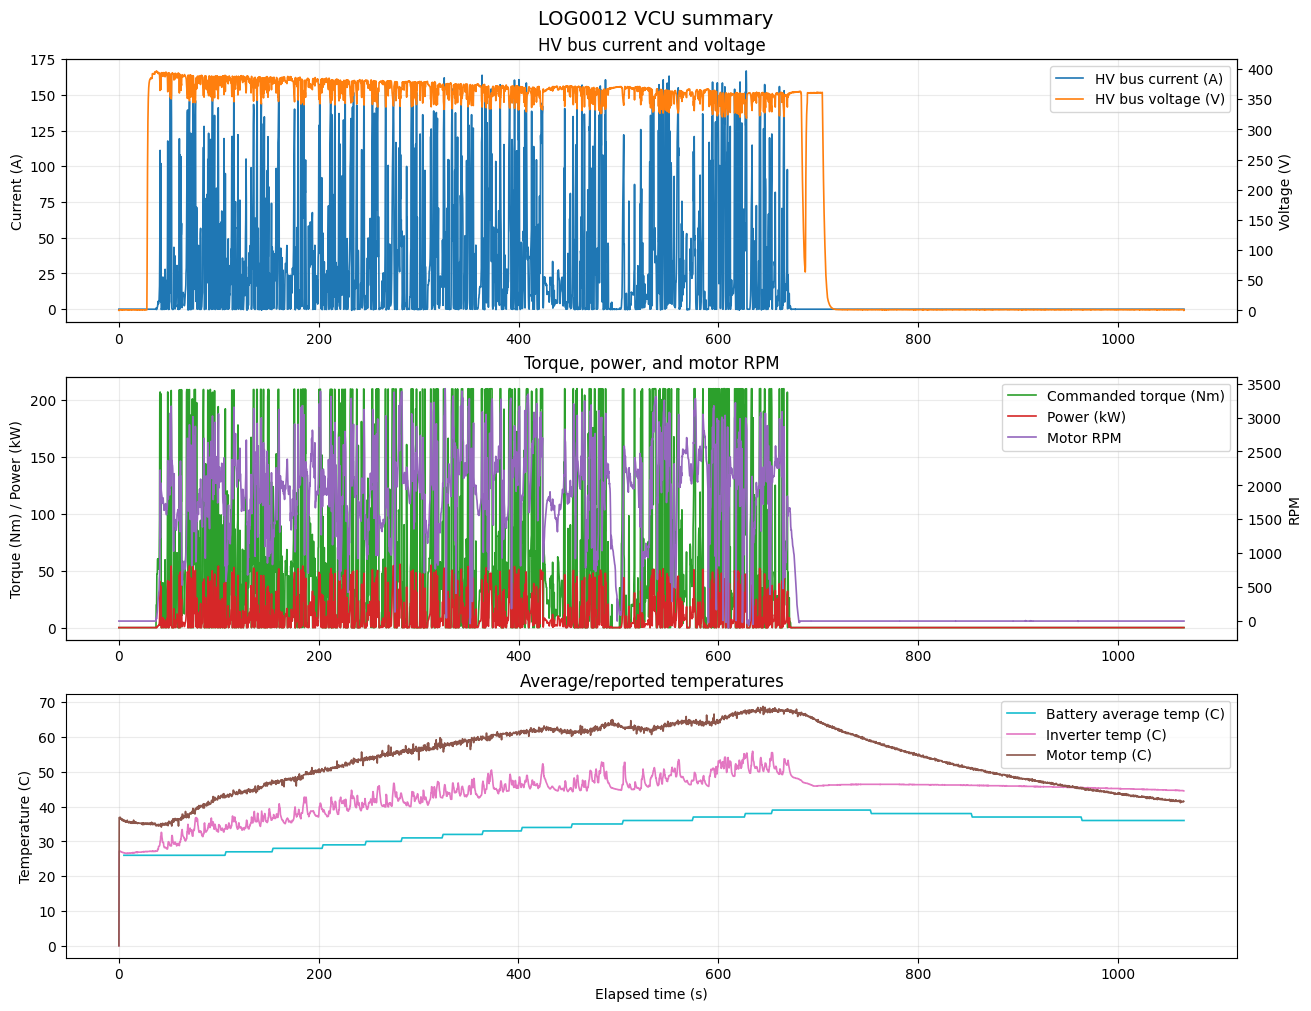


LOG0013
Streams: fast, medium, slow, imu
Rows: fast=5,792, medium=580, slow=59, imu=5,792
Duration: 58.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,5792,0.00,0.0,0.0
1,HV bus voltage,fast,V,5792,1.04,1.6,0.0
2,Commanded torque,fast,Nm,5792,0.00,0.0,0.0
3,Power,medium,kW,580,0.00,0.0,0.0
4,Motor RPM,fast,rpm,5792,0.00,0.0,0.0
5,Avg battery cell temp,slow,C,54,35.17,36.0,35.0
6,Reported battery temp,medium,C,580,37.10,40.0,0.0
7,Inverter temp,medium,C,580,43.84,44.3,0.0
8,Motor temp,medium,C,580,40.31,41.5,0.0


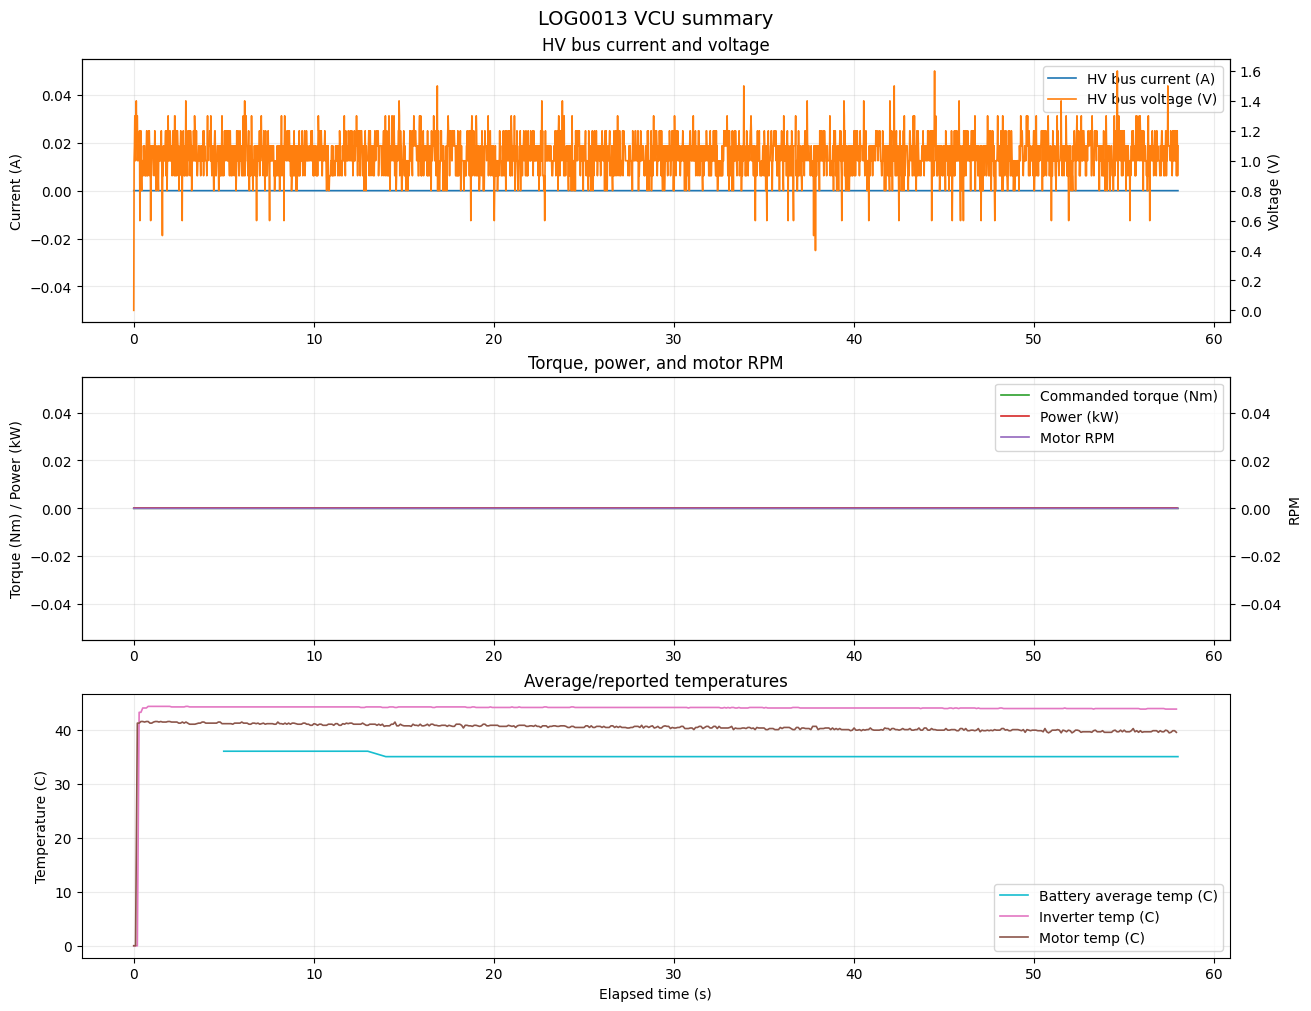


LOG0014
Streams: fast, medium, slow, imu
Rows: fast=5,593, medium=560, slow=57, imu=5,593
Duration: 56.0 s


,signal,stream,unit,samples,average,maximum,minimum
0,HV bus current,fast,A,5593,0.00,0.0,0.0
1,HV bus voltage,fast,V,5593,0.91,1.4,0.0
2,Commanded torque,fast,Nm,5593,0.00,0.0,0.0
3,Power,medium,kW,560,0.00,0.0,0.0
4,Motor RPM,fast,rpm,5593,-0.01,0.0,-1.0
5,Avg battery cell temp,slow,C,53,34.00,34.0,34.0
6,Reported battery temp,medium,C,560,36.59,40.0,0.0
7,Inverter temp,medium,C,560,41.27,41.6,0.0
8,Motor temp,medium,C,560,38.53,40.3,0.0


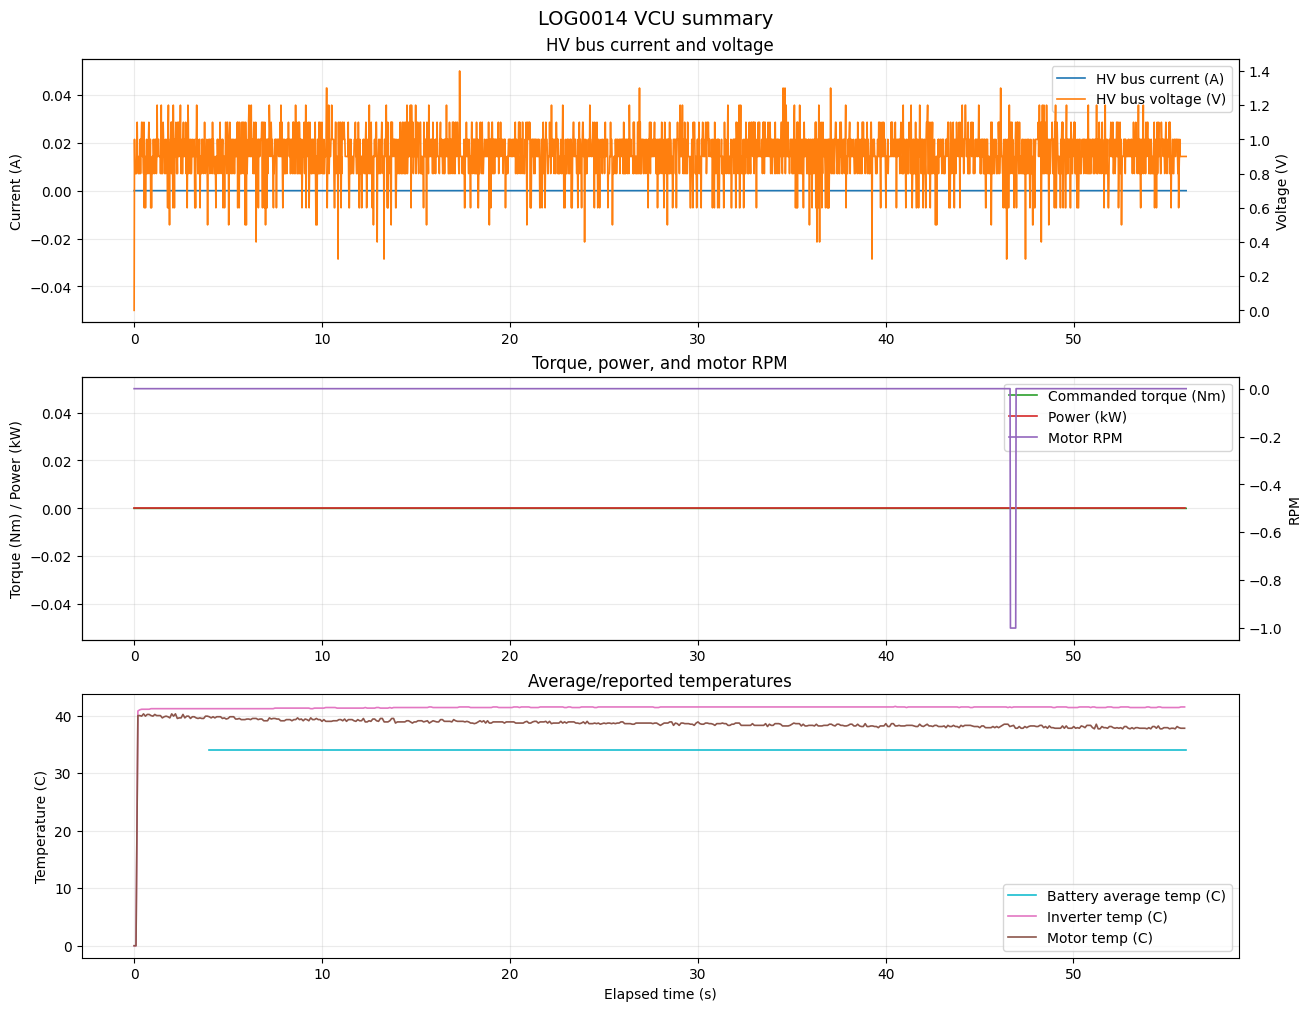

In [3]:
metrics_by_log = summarize_vcu_logs(
    logs,
    log_numbers=LOG_NUMBERS,
    max_points=MAX_POINTS_PER_TRACE,
)
